In [14]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

In [15]:
class AgentState(TypedDict):
    number1 : int
    operation : str
    number2 : int
    number3 : int
    operation2 : str
    number4 : int
    finalNumber : int
    finalNumber2 : int
    

In [16]:
def add_node(state : AgentState) -> AgentState:
    state['finalNumber'] = state['number1'] + state['number2']
    return state
def subtract_node(state : AgentState) -> AgentState:
    state['finalNumber'] = state['number1'] - state['number2']
def Router_two_operation(state : AgentState) -> AgentState:
    if state['operation'] == '+':
        return "addition_operation"
    else :
        return "subtraction_operation"

def add_node2(state : AgentState) -> AgentState:
    state['finalNumber2'] = state['number3'] + state['number4']
    return state
def subtract_node2(state : AgentState) -> AgentState:
    state['finalNumber2'] = state['number3'] - state['number4']
def Router_two_operation2(state : AgentState) -> AgentState:
    if state['operation2'] == '+':
        return "addition_operation2"
    else :
        return "subtraction_operation2"


In [17]:
graph = StateGraph(AgentState)
graph.add_node("adder_node", add_node)
graph.add_node("subtract_node", subtract_node)
graph.add_node("router", lambda state : state)
graph.add_node("adder_node2", add_node2)
graph.add_node("subtract_node2", subtract_node2)
graph.add_node("router2", lambda state : state)
graph.add_edge(START,"router")
graph.add_conditional_edges(
    "router",
    Router_two_operation,
    {
        "addition_operation" : "adder_node",
        "subtraction_operation" : "subtract_node"
    }
)
graph.add_edge("adder_node","router2")
graph.add_edge("subtract_node","router2")
graph.add_conditional_edges(
    "router2",
    Router_two_operation2,
    {
        "addition_operation2" : "adder_node2",
        "subtraction_operation2" : "subtract_node2"
    }
)
graph.add_edge("adder_node2",END)
graph.add_edge("subtract_node2",END)
app = graph.compile()

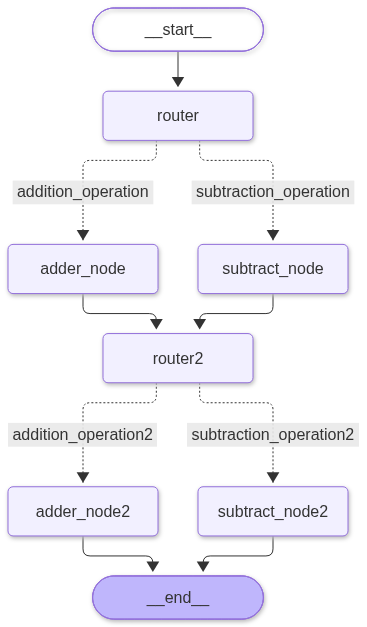

In [18]:
from IPython.display import display,Image
display(Image(app.get_graph().draw_mermaid_png()))

In [19]:
initial_state = AgentState(number1 = 10, operation="-", number2 = 5, number3 = 7, number4=2, operation2="+", finalNumber= 0, finalNumber2 = 0)

In [22]:
print(app.invoke(initial_state))

{'number1': 10, 'operation': '-', 'number2': 5, 'number3': 7, 'operation2': '+', 'number4': 2, 'finalNumber': 0, 'finalNumber2': 9}
